In [1]:
import pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.autograd import Function
from sklearn.metrics import (
    classification_report, f1_score, roc_auc_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt
from autogluon.tabular import TabularPredictor

In [2]:
with open('wdd/processed_data.pkl', 'rb') as f:
    data_wdd = pickle.load(f)
X_wdd = data_wdd['X']
y_wdd = data_wdd['y']

with open('output/processed_data_anxolotl.pkl', 'rb') as f:
    data_anx = pickle.load(f)
X_anx = data_anx['X']
y_anx = data_anx['y']

In [3]:
with open('wesad/processed_data.pkl', 'rb') as f:
    data_wesad = pickle.load(f)

print("WESAD features:", data_wesad['feature_cols'][:10])
print("WESAD n_features:", len(data_wesad['feature_cols']))

print("\nWDD features:", data_wdd['feature_cols'][:10])
print("WDD n_features:", len(data_wdd['feature_cols']))

print("\nAnxolotl features:", data_anx['feature_cols'][:10])
print("Anxolotl n_features:", len(data_anx['feature_cols']))

# verificar se as colunas comuns estão na mesma ordem
wesad_cols = set(data_wesad['feature_cols'])
wdd_cols = set(data_wdd['feature_cols'])
print("\nFeatures no WDD que não existem no WESAD:", wdd_cols - wesad_cols)
print("Features no WESAD que não existem no WDD:", wesad_cols - wdd_cols)

WESAD features: ['acc_wrist_mean', 'acc_wrist_std', 'acc_wrist_min', 'acc_wrist_max', 'acc_wrist_p25', 'acc_wrist_p75', 'acc_wrist_skew', 'acc_wrist_kurtosis', 'acc_chest_mean', 'acc_chest_std']
WESAD n_features: 137

WDD features: ['acc_wrist_mean', 'acc_wrist_std', 'acc_wrist_min', 'acc_wrist_max', 'acc_wrist_p25', 'acc_wrist_p75', 'acc_wrist_skew', 'acc_wrist_kurtosis', 'acc_wrist_slope', 'acc_wrist_abs_mean']
WDD n_features: 90

Anxolotl features: ['acc_wrist_mean', 'acc_wrist_std', 'acc_wrist_min', 'acc_wrist_max', 'acc_wrist_p25', 'acc_wrist_p75', 'acc_wrist_skew', 'acc_wrist_kurtosis', 'acc_wrist_slope', 'acc_wrist_abs_mean']
Anxolotl n_features: 60

Features no WDD que não existem no WESAD: {'rmssd_abs_mean', 'eda_wrist_abs_mean', 'temp_wrist_delta_mean', 'temp_wrist_abs_mean', 'temp_wrist_lf_hf', 'acc_wrist_delta_mean', 'acc_wrist_abs_mean', 'sdnn_lf_hf', 'sdnn_slope', 'eda_wrist_peak_amp', 'temp_wrist_slope', 'sdnn_abs_mean', 'ibi_abs_mean', 'acc_wrist_slope', 'rmssd_slope', 

In [4]:
with open('lgbm_wrist_final.pkl', 'rb') as f:
    lgbm_data = pickle.load(f)

with open('ensemble_wrist_final.pkl', 'rb') as f:
    ensemble_data = pickle.load(f)

/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1

/tmp/ipykernel_47270/1743086110.py:5: UserWarning: [21:29:15] WARNING: /workspace/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  ensemble_data = pickle.load(f)
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator VotingClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
class RNN1D(nn.Module):
    def __init__(self, input_size=5, hidden_size=128, num_layers=2, num_classes=2):
        super().__init__()
        self.rnn = nn.GRU(input_size=input_size, hidden_size=hidden_size,
                          num_layers=num_layers, batch_first=True,
                          dropout=0.3, bidirectional=True)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, num_classes)
        )
    def forward(self, x):
        x = x.permute(0, 2, 1)
        out, _ = self.rnn(x)
        return self.classifier(out[:, -1, :])

In [6]:
class GRL(Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x
    @staticmethod
    def backward(ctx, grad):
        return grad.neg() * ctx.lam, None

class FeatureExtractor(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU()
        )
    def forward(self, x):
        return self.rede(x)

class StressClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 2)
        )
    def forward(self, x):
        return self.rede(x)

class DomainDiscriminator(nn.Module):
    def __init__(self, n_subjects):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_subjects)
        )
    def forward(self, x, lam):
        return self.rede(GRL.apply(x, lam))

class DANN(nn.Module):
    def __init__(self, n_features, n_subjects):
        super().__init__()
        self.extractor  = FeatureExtractor(n_features)
        self.stress_cls = StressClassifier()
        self.domain_dis = DomainDiscriminator(n_subjects)
    def forward(self, x, lam):
        z = self.extractor(x)
        return self.stress_cls(z), self.domain_dis(z, lam)

In [7]:
device = torch.device('cpu')

rnn_ckpt  = torch.load('rnn_wrist_final.pt',  map_location=device, weights_only=False)
dann_ckpt = torch.load('dann_wrist_final.pt', map_location=device, weights_only=False)

rnn_model = RNN1D(input_size=5).to(device)
rnn_model.load_state_dict(rnn_ckpt['model_state_dict'])
rnn_model.eval()

dann_model = DANN(n_features=20, n_subjects=15).to(device)
dann_model.load_state_dict(dann_ckpt['model_state_dict'])
dann_model.eval()

DANN(
  (extractor): FeatureExtractor(
    (rede): Sequential(
      (0): Linear(in_features=20, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=64, bias=True)
      (3): ReLU()
    )
  )
  (stress_cls): StressClassifier(
    (rede): Sequential(
      (0): Linear(in_features=64, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=2, bias=True)
    )
  )
  (domain_dis): DomainDiscriminator(
    (rede): Sequential(
      (0): Linear(in_features=64, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=15, bias=True)
    )
  )
)

In [8]:
def print_metrics(y_true, y_pred, y_prob, model_name, dataset_name):
    print(f"\n{'='*55}")
    print(f"  {model_name} — {dataset_name}")
    print(f"{'='*55}")
    print(classification_report(y_true, y_pred,
                                target_names=['baseline', 'stress'],
                                zero_division=0))
    print(f"Macro F1:  {f1_score(y_true, y_pred, average='macro'):.3f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.3f}")
    print(f"Bal. Acc:  {balanced_accuracy_score(y_true, y_pred):.3f}")
    print(f"MCC:       {matthews_corrcoef(y_true, y_pred):.3f}")

    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_true, y_pred),
                annot=True, fmt='d', cmap='Blues',
                xticklabels=['baseline', 'stress'],
                yticklabels=['baseline', 'stress'])
    plt.title(f'{model_name} — {dataset_name}')
    plt.tight_layout()
    plt.show()

In [9]:
def eval_sklearn(model_data, X, y, model_name, dataset_name):
    cols = model_data['feature_cols']
    
    X_df = pd.DataFrame(X).copy()
    
    # renomear acc_energy → acc_wrist no Anxolotl
    X_df = X_df.rename(columns={
        c: c.replace('acc_energy_', 'acc_wrist_')
        for c in X_df.columns if c.startswith('acc_energy_')
    })
    
    # adicionar colunas que faltam como NaN
    for col in cols:
        if col not in X_df.columns:
            X_df[col] = np.nan
    
    X_sel = X_df[cols]
    X_sc  = model_data['imputer'].transform(
                model_data['scaler'].transform(X_sel))
    y_pred = model_data['model'].predict(X_sc)
    y_prob = model_data['model'].predict_proba(X_sc)[:, 1]
    print_metrics(y, y_pred, y_prob, model_name, dataset_name)

In [10]:
def eval_rnn(model, X_seq, y_seq, model_name, dataset_name, channel_idx=None):
    if channel_idx is not None:
        X_seq = X_seq[:, channel_idx, :]
    X_t = torch.tensor(X_seq, dtype=torch.float32)
    with torch.no_grad():
        logits = []
        for i in range(0, len(X_t), 64):
            batch = X_t[i:i+64].to(device)
            logits.append(model(batch).cpu())
        logits = torch.cat(logits)
    probs  = torch.softmax(logits, dim=1)[:, 1].numpy()
    y_pred = logits.argmax(1).numpy()
    print_metrics(y_seq, y_pred, probs, model_name, dataset_name)

In [11]:
def eval_dann(model, X, y, scaler, imputer, top_k_idx, feature_cols_dann, model_name, dataset_name):
    X_df = pd.DataFrame(X).copy()
    
    # renomear acc_energy → acc_wrist
    X_df = X_df.rename(columns={
        c: c.replace('acc_energy_', 'acc_wrist_')
        for c in X_df.columns if c.startswith('acc_energy_')
    })
    
    # adicionar colunas que faltam como NaN
    for col in feature_cols_dann:
        if col not in X_df.columns:
            X_df[col] = np.nan
    
    X_sel = X_df[feature_cols_dann]
    X_sc  = imputer.transform(scaler.transform(X_sel))
    X_sel2 = X_sc[:, top_k_idx]
    X_t   = torch.tensor(X_sel2, dtype=torch.float32)
    with torch.no_grad():
        logits = []
        for i in range(0, len(X_t), 64):
            batch = X_t[i:i+64].to(device)
            stress_out, _ = model(batch, lam=0)
            logits.append(stress_out.cpu())
        logits = torch.cat(logits)
    probs  = torch.softmax(logits, dim=1)[:, 1].numpy()
    y_pred = logits.argmax(1).numpy()
    print_metrics(y, y_pred, probs, model_name, dataset_name)

In [12]:
def eval_autogluon(predictor_path, X, y, model_name, dataset_name):
    predictor = TabularPredictor.load(predictor_path)
    
    # adicionar colunas que faltam como NaN
    X_df = pd.DataFrame(X).copy()
    for col in predictor.feature_metadata_in.get_features():
        if col not in X_df.columns:
            X_df[col] = np.nan
    
    y_pred = predictor.predict(X_df).values
    y_prob = predictor.predict_proba(X_df).iloc[:, 1].values
    print_metrics(y, y_pred, y_prob, model_name, dataset_name)


  CROSS-DATASET — WDD

  LightGBM — WDD
              precision    recall  f1-score   support

    baseline       0.18      0.60      0.28      1159
      stress       0.75      0.31      0.44      4436

    accuracy                           0.37      5595
   macro avg       0.47      0.45      0.36      5595
weighted avg       0.63      0.37      0.40      5595

Macro F1:  0.359
ROC-AUC:   0.425
Bal. Acc:  0.453
MCC:       -0.080


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


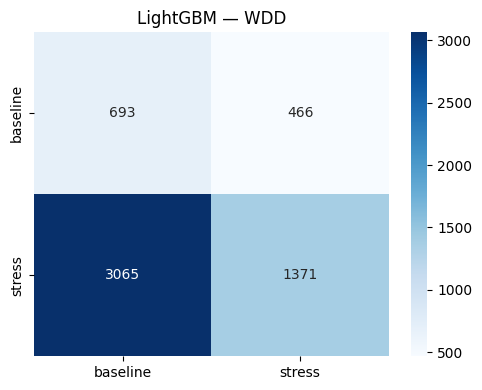

/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



  Ensemble — WDD
              precision    recall  f1-score   support

    baseline       0.20      0.68      0.30      1159
      stress       0.76      0.26      0.39      4436

    accuracy                           0.35      5595
   macro avg       0.48      0.47      0.35      5595
weighted avg       0.65      0.35      0.37      5595

Macro F1:  0.349
ROC-AUC:   0.413
Bal. Acc:  0.475
MCC:       -0.046


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


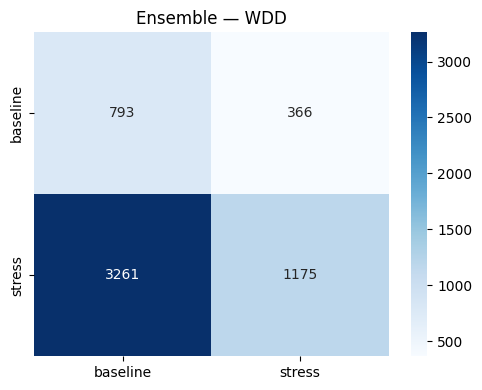


  RNN — WDD
              precision    recall  f1-score   support

    baseline       0.17      0.53      0.26      1159
      stress       0.73      0.34      0.47      4436

    accuracy                           0.38      5595
   macro avg       0.45      0.43      0.36      5595
weighted avg       0.62      0.38      0.42      5595

Macro F1:  0.364
ROC-AUC:   0.421
Bal. Acc:  0.434
MCC:       -0.110


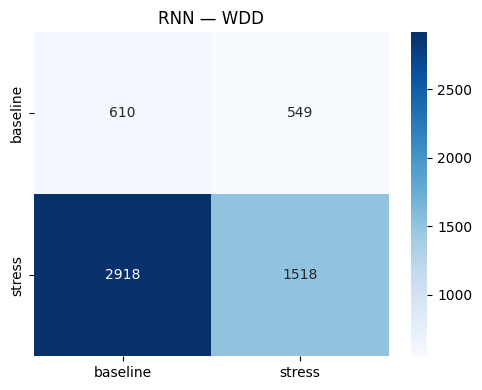


  DANN — WDD
              precision    recall  f1-score   support

    baseline       0.20      0.63      0.31      1159
      stress       0.78      0.35      0.48      4436

    accuracy                           0.41      5595
   macro avg       0.49      0.49      0.39      5595
weighted avg       0.66      0.41      0.44      5595

Macro F1:  0.393
ROC-AUC:   0.588
Bal. Acc:  0.490
MCC:       -0.017


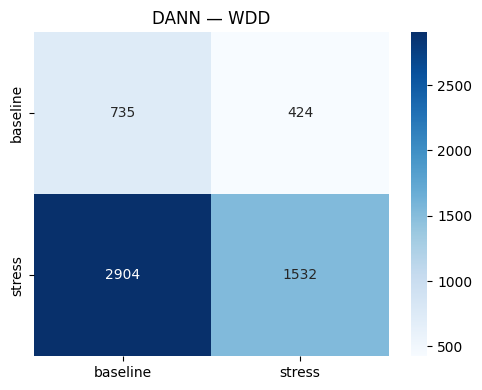


  AutoGluon — WDD
              precision    recall  f1-score   support

    baseline       0.21      0.99      0.34      1159
      stress       0.87      0.02      0.04      4436

    accuracy                           0.22      5595
   macro avg       0.54      0.50      0.19      5595
weighted avg       0.73      0.22      0.10      5595

Macro F1:  0.192
ROC-AUC:   0.530
Bal. Acc:  0.504
MCC:       0.026


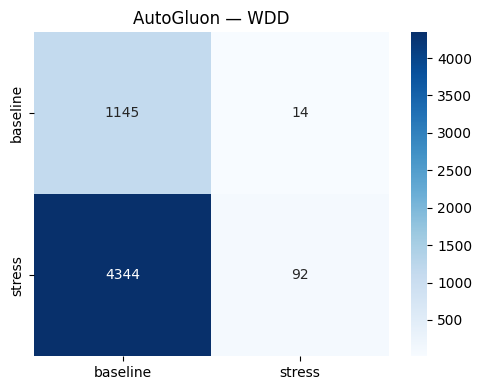

In [13]:
print("\n" + "="*55)
print("  CROSS-DATASET — WDD")
print("="*55)

# carregar sequências do WDD para RNN e DANN
with open('wdd/processed_data_sequences.pkl', 'rb') as f:
    data_wdd_seq = pickle.load(f)
X_wdd_seq = data_wdd_seq['X_seq']
y_wdd_seq = data_wdd_seq['y_seq']

eval_sklearn(lgbm_data,     X_wdd, y_wdd, 'LightGBM', 'WDD')
eval_sklearn(ensemble_data, X_wdd, y_wdd, 'Ensemble', 'WDD')
eval_rnn(rnn_model, X_wdd_seq, y_wdd_seq, 'RNN', 'WDD', channel_idx=[0, 3, 4, 5, 6])
eval_dann(dann_model, X_wdd, y_wdd,
          dann_ckpt['scaler'], dann_ckpt['imputer'], dann_ckpt['top_k_idx'],
          dann_ckpt['feature_cols'],
          'DANN', 'WDD')
eval_autogluon('autogluon_wrist_final', X_wdd, y_wdd, 'AutoGluon', 'WDD')


  CROSS-DATASET — ANXOLOTL

  LightGBM — Anxolotl
              precision    recall  f1-score   support

    baseline       0.42      1.00      0.60       235
      stress       0.00      0.00      0.00       318

    accuracy                           0.42       553
   macro avg       0.21      0.50      0.30       553
weighted avg       0.18      0.42      0.25       553

Macro F1:  0.298
ROC-AUC:   0.541
Bal. Acc:  0.500
MCC:       0.000


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


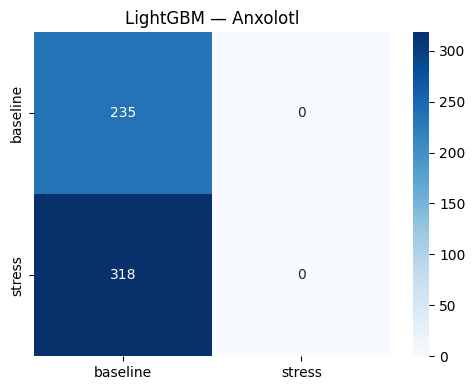


  Ensemble — Anxolotl
              precision    recall  f1-score   support

    baseline       0.49      0.56      0.52       235
      stress       0.63      0.56      0.60       318

    accuracy                           0.56       553
   macro avg       0.56      0.56      0.56       553
weighted avg       0.57      0.56      0.56       553

Macro F1:  0.557
ROC-AUC:   0.553
Bal. Acc:  0.560
MCC:       0.119


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


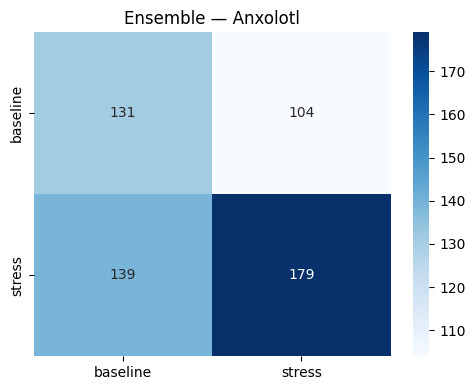


  RNN — Anxolotl
              precision    recall  f1-score   support

    baseline       0.49      0.42      0.45      7032
      stress       0.59      0.66      0.63      9115

    accuracy                           0.55     16147
   macro avg       0.54      0.54      0.54     16147
weighted avg       0.55      0.55      0.55     16147

Macro F1:  0.538
ROC-AUC:   0.540
Bal. Acc:  0.539
MCC:       0.080


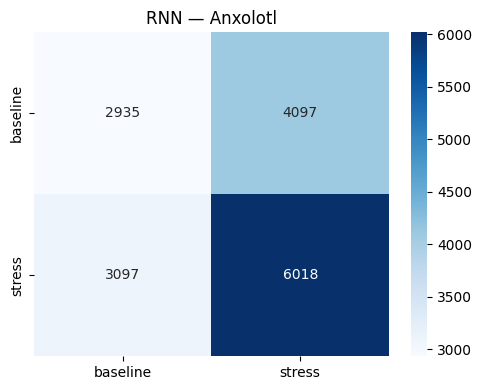


  DANN — Anxolotl
              precision    recall  f1-score   support

    baseline       0.42      1.00      0.60       235
      stress       0.00      0.00      0.00       318

    accuracy                           0.42       553
   macro avg       0.21      0.50      0.30       553
weighted avg       0.18      0.42      0.25       553

Macro F1:  0.298
ROC-AUC:   0.505
Bal. Acc:  0.500
MCC:       0.000


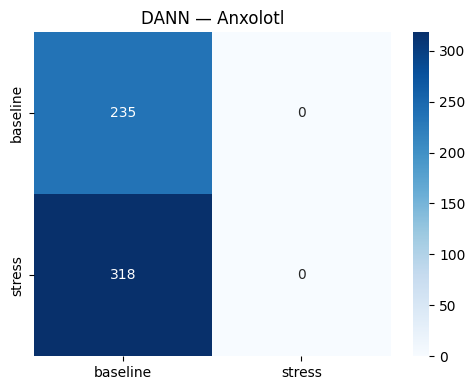


  AutoGluon — Anxolotl
              precision    recall  f1-score   support

    baseline       0.42      1.00      0.60       235
      stress       0.00      0.00      0.00       318

    accuracy                           0.42       553
   macro avg       0.21      0.50      0.30       553
weighted avg       0.18      0.42      0.25       553

Macro F1:  0.298
ROC-AUC:   0.542
Bal. Acc:  0.500
MCC:       0.000


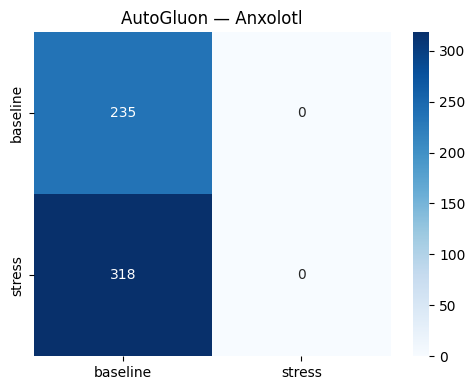

In [14]:
print("\n" + "="*55)
print("  CROSS-DATASET — ANXOLOTL")
print("="*55)

# carregar sequências do Anxolotl para RNN e DANN
with open('output/processed_data_anxolotl_seq.pkl', 'rb') as f:
    data_anx_seq = pickle.load(f)
X_anx_seq = data_anx_seq['X_seq']
y_anx_seq = data_anx_seq['y_seq']

eval_sklearn(lgbm_data,     X_anx, y_anx, 'LightGBM', 'Anxolotl')
eval_sklearn(ensemble_data, X_anx, y_anx, 'Ensemble', 'Anxolotl')
eval_rnn(rnn_model, X_anx_seq, y_anx_seq, 'RNN', 'Anxolotl')
eval_dann(dann_model, X_anx, y_anx,
          dann_ckpt['scaler'], dann_ckpt['imputer'], dann_ckpt['top_k_idx'],
          dann_ckpt['feature_cols'],
          'DANN', 'Anxolotl')
eval_autogluon('autogluon_wrist_final', X_anx, y_anx, 'AutoGluon', 'Anxolotl')

In [15]:
from sklearn.metrics import roc_curve, auc as sklearn_auc

def get_sklearn_probs(model_data, X):
    cols = model_data['feature_cols']
    X_df = pd.DataFrame(X).copy()
    for col in cols:
        if col not in X_df.columns:
            X_df[col] = np.nan
    X_sel = X_df[cols]
    X_sc  = model_data['imputer'].transform(model_data['scaler'].transform(X_sel))
    return model_data['model'].predict_proba(X_sc)[:, 1]

def get_dann_probs(model, X, scaler, imputer, top_k_idx, feature_cols_dann):
    X_df = pd.DataFrame(X).copy()
    for col in feature_cols_dann:
        if col not in X_df.columns:
            X_df[col] = np.nan
    X_sc   = imputer.transform(scaler.transform(X_df[feature_cols_dann]))
    X_t    = torch.tensor(X_sc[:, top_k_idx], dtype=torch.float32)
    logits = []
    with torch.no_grad():
        for i in range(0, len(X_t), 64):
            out, _ = model(X_t[i:i+64].to(device), lam=0)
            logits.append(out.cpu())
    return torch.softmax(torch.cat(logits), dim=1)[:, 1].numpy()

def get_rnn_probs(model, X_seq, channel_idx=None):
    if channel_idx is not None:
        X_seq = X_seq[:, channel_idx, :]
    X_t = torch.tensor(X_seq, dtype=torch.float32)
    logits = []
    with torch.no_grad():
        for i in range(0, len(X_t), 64):
            logits.append(model(X_t[i:i+64].to(device)).cpu())
    return torch.softmax(torch.cat(logits), dim=1)[:, 1].numpy()

def get_autogluon_probs(predictor_path, X):
    from autogluon.tabular import TabularPredictor
    predictor = TabularPredictor.load(predictor_path)
    X_df = pd.DataFrame(X).copy()
    for col in predictor.feature_metadata_in.get_features():
        if col not in X_df.columns:
            X_df[col] = np.nan
    return predictor.predict_proba(X_df).iloc[:, 1].values

def find_threshold(y_true, y_prob):
    """Threshold ótimo pelo critério de Youden (maximiza TPR - FPR)."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    best = np.argmax(tpr - fpr)
    return float(thresholds[best])

def metrics_at_threshold(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        'f1':      f1_score(y_true, y_pred, average='macro', zero_division=0),
        'bal_acc': balanced_accuracy_score(y_true, y_pred),
        'mcc':     matthews_corrcoef(y_true, y_pred),
    }

/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


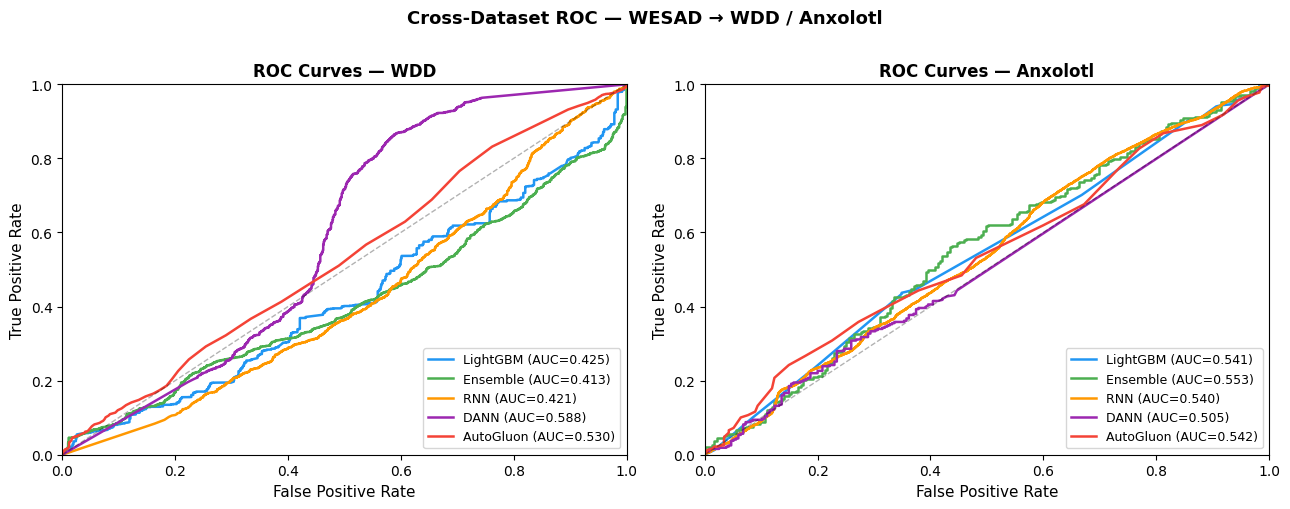

In [16]:
# Carregar sequências (se não estiverem já em memória)
with open('wdd/processed_data_sequences.pkl', 'rb') as f:
    _wdd_seq = pickle.load(f)
with open('output/processed_data_anxolotl_seq.pkl', 'rb') as f:
    _anx_seq = pickle.load(f)

# (model, probs, y_true) — RNN usa y das sequences, modelos tabulares usam y tabular
_entries = {
    'WDD': [
        ('LightGBM',  get_sklearn_probs(lgbm_data,     data_wdd['X']), np.array(data_wdd['y'])),
        ('Ensemble',   get_sklearn_probs(ensemble_data, data_wdd['X']), np.array(data_wdd['y'])),
        ('RNN',        get_rnn_probs(rnn_model, _wdd_seq['X_seq'], channel_idx=[0,3,4,5,6]), _wdd_seq['y_seq']),
        ('DANN',       get_dann_probs(dann_model, data_wdd['X'], dann_ckpt['scaler'],
                           dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols']),
                       np.array(data_wdd['y'])),
        ('AutoGluon',  get_autogluon_probs('autogluon_wrist_final', data_wdd['X']), np.array(data_wdd['y'])),
    ],
    'Anxolotl': [
        ('LightGBM',  get_sklearn_probs(lgbm_data,     data_anx['X']), np.array(data_anx['y'])),
        ('Ensemble',   get_sklearn_probs(ensemble_data, data_anx['X']), np.array(data_anx['y'])),
        ('RNN',        get_rnn_probs(rnn_model, _anx_seq['X_seq']), _anx_seq['y_seq']),
        ('DANN',       get_dann_probs(dann_model, data_anx['X'], dann_ckpt['scaler'],
                           dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols']),
                       np.array(data_anx['y'])),
        ('AutoGluon',  get_autogluon_probs('autogluon_wrist_final', data_anx['X']), np.array(data_anx['y'])),
    ],
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {'LightGBM':'#2196F3','Ensemble':'#4CAF50','RNN':'#FF9800','DANN':'#9C27B0','AutoGluon':'#F44336'}

for ax, ds in zip(axes, ['WDD', 'Anxolotl']):
    for model, p, y_true in _entries[ds]:
        fpr, tpr, _ = roc_curve(y_true, p)
        auc_val = sklearn_auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f'{model} (AUC={auc_val:.3f})', color=colors[model], linewidth=1.8)
    ax.plot([0,1],[0,1],'k--',alpha=0.3,linewidth=1)
    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.set_title(f'ROC Curves — {ds}', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.set_xlim([0,1]); ax.set_ylim([0,1])

plt.suptitle('Cross-Dataset ROC — WESAD → WDD / Anxolotl', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [17]:
print("="*94)
print("  THRESHOLD CALIBRATION — Default (0.50) vs Óptimo (Youden J)")
print("  threshold ótimo calculado no dataset de teste = upper bound")
print("="*94)
print(f"{'Modelo':<12} {'Dataset':<10} {'AUC':>6}  {'F1(0.50)':>8} {'F1(opt)':>8}  {'MCC(0.50)':>9} {'MCC(opt)':>9}  {'Thresh':>7}")
print('-'*94)

for ds in ['WDD', 'Anxolotl']:
    for model, p, y_true in _entries[ds]:
        auc_val = sklearn_auc(*roc_curve(y_true, p)[:2])
        t_opt   = find_threshold(y_true, p)
        m_def   = metrics_at_threshold(y_true, p, 0.50)
        m_opt   = metrics_at_threshold(y_true, p, t_opt)
        print(f"{model:<12} {ds:<10} {auc_val:>6.3f}  "
              f"{m_def['f1']:>8.3f} {m_opt['f1']:>8.3f}  "
              f"{m_def['mcc']:>9.3f} {m_opt['mcc']:>9.3f}  "
              f"{t_opt:>7.3f}")
    print()

  THRESHOLD CALIBRATION — Default (0.50) vs Óptimo (Youden J)
  threshold ótimo calculado no dataset de teste = upper bound
Modelo       Dataset       AUC  F1(0.50)  F1(opt)  MCC(0.50)  MCC(opt)   Thresh
----------------------------------------------------------------------------------------------
LightGBM     WDD         0.425     0.359    0.226     -0.080     0.054    0.959
Ensemble     WDD         0.413     0.349    0.218     -0.046     0.072    0.976
RNN          WDD         0.421     0.364    0.482     -0.110     0.010    0.000
DANN         WDD         0.588     0.393    0.642     -0.017     0.284    0.000
AutoGluon    WDD         0.530     0.194    0.536      0.029     0.073    0.287

LightGBM     Anxolotl    0.541     0.298    0.528      0.000     0.089    0.395
Ensemble     Anxolotl    0.553     0.557    0.559      0.119     0.124    0.501
RNN          Anxolotl    0.540     0.538    0.536      0.080     0.091    0.338
DANN         Anxolotl    0.505     0.298    0.482      0.000

In [18]:
# ── Experimento: WESAD Scaler vs Normalização por Dataset ────────────────────
# Hipótese: parte do erro é shift de hardware/população (Apple Watch vs E4),
# não shift fisiológico real. Remover o offset sistemático deve melhorar.
#
# Método: z-score por coluna usando estatísticas do próprio dataset de teste.
# Usa-se só o imputer do WESAD para features em falta (→ 0 = média).
# Não usa labels → aplicável sem supervisão no domínio alvo.

from sklearn.preprocessing import StandardScaler as _SS

def _target_scale(X_df_with_nans):
    X = X_df_with_nans.values.astype(float).copy()
    for j in range(X.shape[1]):
        col = X[:, j]
        valid = col[~np.isnan(col)]
        if len(valid) > 1:
            mu, sd = valid.mean(), valid.std()
            X[:, j] = (col - mu) / (sd + 1e-8)
    return X

def get_probs_target_scaler(model_data, X):
    cols = model_data['feature_cols']
    X_df = pd.DataFrame(X).copy()
    for col in cols:
        if col not in X_df.columns: X_df[col] = np.nan
    X_norm = _target_scale(X_df[cols])
    X_sc   = model_data['imputer'].transform(X_norm)
    return model_data['model'].predict_proba(X_sc)[:, 1]

def get_dann_probs_target(model, X, imputer, top_k_idx, fc):
    X_df = pd.DataFrame(X).copy()
    for col in fc:
        if col not in X_df.columns: X_df[col] = np.nan
    X_norm = _target_scale(X_df[fc])
    X_sc   = imputer.transform(X_norm)
    X_t    = torch.tensor(X_sc[:, top_k_idx], dtype=torch.float32)
    logits = []
    with torch.no_grad():
        for i in range(0, len(X_t), 64):
            out, _ = model(X_t[i:i+64].to(device), lam=0)
            logits.append(out.cpu())
    return torch.softmax(torch.cat(logits), dim=1)[:, 1].numpy()

# ── resultados para o Anxolotl ────────────────────────────────
_y = np.array(data_anx['y'])

_norm_entries = {
    'LightGBM': (get_sklearn_probs(lgbm_data,     data_anx['X']),
                 get_probs_target_scaler(lgbm_data,     data_anx['X'])),
    'Ensemble':  (get_sklearn_probs(ensemble_data, data_anx['X']),
                 get_probs_target_scaler(ensemble_data, data_anx['X'])),
    'DANN':      (get_dann_probs(dann_model, data_anx['X'], dann_ckpt['scaler'],
                     dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols']),
                 get_dann_probs_target(dann_model, data_anx['X'],
                     dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols'])),
}

print("="*82)
print("  NORMALIZAÇÃO POR DATASET — Anxolotl")
print("  WESAD scaler  vs  z-score por dataset (unsupervised, threshold de Youden)")
print("="*82)
print(f"{'Modelo':<12}  {'AUC wesad':>9} {'AUC target':>10}  "
      f"{'F1 wesad':>9} {'F1 target':>10}  {'MCC wesad':>9} {'MCC target':>10}")
print('-'*82)

for model, (p_w, p_t) in _norm_entries.items():
    auc_w = sklearn_auc(*roc_curve(_y, p_w)[:2])
    auc_t = sklearn_auc(*roc_curve(_y, p_t)[:2])
    t_w   = find_threshold(_y, p_w);  m_w = metrics_at_threshold(_y, p_w, t_w)
    t_t   = find_threshold(_y, p_t);  m_t = metrics_at_threshold(_y, p_t, t_t)
    da = auc_t - auc_w;  df = m_t['f1'] - m_w['f1']
    sa = '+' if da >= 0 else ''; sf = '+' if df >= 0 else ''
    print(f"{model:<12}  {auc_w:>9.3f} {auc_t:>7.3f}({sa}{da:.3f})"
          f"  {m_w['f1']:>9.3f} {m_t['f1']:>7.3f}({sf}{df:.3f})"
          f"  {m_w['mcc']:>9.3f} {m_t['mcc']:>10.3f}")

print()
print("Interpretação:")
print("  Δ positivo = normalização por dataset ajuda → shift era de calibração/hardware")
print("  Δ pequeno  = shift fisiológico real (lab stress ≠ ansiedade naturalística)")

  NORMALIZAÇÃO POR DATASET — Anxolotl
  WESAD scaler  vs  z-score por dataset (unsupervised, threshold de Youden)
Modelo        AUC wesad AUC target   F1 wesad  F1 target  MCC wesad MCC target
----------------------------------------------------------------------------------
LightGBM          0.541   0.576(+0.035)      0.528   0.571(+0.044)      0.089      0.143
Ensemble          0.553   0.572(+0.019)      0.559   0.565(+0.005)      0.124      0.134
DANN              0.505   0.590(+0.084)      0.482   0.582(+0.100)      0.053      0.164

Interpretação:
  Δ positivo = normalização por dataset ajuda → shift era de calibração/hardware
  Δ pequeno  = shift fisiológico real (lab stress ≠ ansiedade naturalística)


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [19]:
# ── LOSO-CV: Tecto Teórico por Dataset ───────────────────────────────────────
# LightGBM treinado no próprio dataset (Leave-One-Subject-Out)
# Estabelece o limite superior: o melhor possível se tivéssemos dados do domínio alvo

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import SimpleImputer as _Imp
import lightgbm as _lgb

def loso_cv_lgbm(data):
    X_df  = data['X'][data['feature_cols']]
    y     = np.array(data['y'])
    grp   = np.array(data['groups'])
    probs = np.zeros(len(y))
    for tr, te in LeaveOneGroupOut().split(X_df.values, y, grp):
        X_tr = X_df.values[tr].astype(float)
        X_te = X_df.values[te].astype(float)
        imp  = _Imp(strategy='mean')
        X_tr = imp.fit_transform(X_tr);  X_te = imp.transform(X_te)
        clf  = _lgb.LGBMClassifier(n_estimators=200, max_depth=4, num_leaves=31,
                                    class_weight='balanced', random_state=42, verbose=-1)
        clf.fit(X_tr, y[tr])
        probs[te] = clf.predict_proba(X_te)[:, 1]
    return probs, y

print("=" * 65)
print("  LOSO-CV — Tecto Teórico (LightGBM treinado no target dataset)")
print("=" * 65)

loso_results = {}
for ds_name, data in [('WDD', data_wdd), ('Anxolotl', data_anx)]:
    probs, y = loso_cv_lgbm(data)
    t  = find_threshold(y, probs)
    p  = (probs >= t).astype(int)
    loso_results[ds_name] = {
        'auc': sklearn_auc(*roc_curve(y, probs)[:2]),
        'f1':  f1_score(y, p, average='macro'),
        'ba':  balanced_accuracy_score(y, p),
        'mcc': matthews_corrcoef(y, p),
    }
    r = loso_results[ds_name]
    print(f"  {ds_name:<10}: AUC={r['auc']:.3f}  F1={r['f1']:.3f}  "
          f"BalAcc={r['ba']:.3f}  MCC={r['mcc']:.3f}")

# ─── Normalização por Dataset — WDD (paralelo à célula 17 para o Anxolotl) ───
_y_wdd = np.array(data_wdd['y'])

_norm_wdd = {
    'LightGBM': (get_sklearn_probs(lgbm_data,     data_wdd['X']),
                 get_probs_target_scaler(lgbm_data,     data_wdd['X'])),
    'Ensemble':  (get_sklearn_probs(ensemble_data, data_wdd['X']),
                 get_probs_target_scaler(ensemble_data, data_wdd['X'])),
    'DANN':      (get_dann_probs(dann_model, data_wdd['X'], dann_ckpt['scaler'],
                     dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols']),
                 get_dann_probs_target(dann_model, data_wdd['X'],
                     dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols'])),
}

print()
print("=" * 82)
print("  NORMALIZAÇÃO POR DATASET — WDD")
print("  WESAD scaler  vs  z-score por dataset (unsupervised, threshold de Youden)")
print("=" * 82)
print(f"{'Modelo':<12}  {'AUC wesad':>9} {'AUC target':>10}  "
      f"{'F1 wesad':>9} {'F1 target':>10}  {'MCC wesad':>9} {'MCC target':>10}")
print('-' * 82)

for model, (p_w, p_t) in _norm_wdd.items():
    auc_w = sklearn_auc(*roc_curve(_y_wdd, p_w)[:2])
    auc_t = sklearn_auc(*roc_curve(_y_wdd, p_t)[:2])
    t_w   = find_threshold(_y_wdd, p_w);  m_w = metrics_at_threshold(_y_wdd, p_w, t_w)
    t_t   = find_threshold(_y_wdd, p_t);  m_t = metrics_at_threshold(_y_wdd, p_t, t_t)
    da = auc_t - auc_w;  df = m_t['f1'] - m_w['f1']
    sa = '+' if da >= 0 else '';  sf = '+' if df >= 0 else ''
    print(f"{model:<12}  {auc_w:>9.3f} {auc_t:>7.3f}({sa}{da:.3f})"
          f"  {m_w['f1']:>9.3f} {m_t['f1']:>7.3f}({sf}{df:.3f})"
          f"  {m_w['mcc']:>9.3f} {m_t['mcc']:>10.3f}")


  LOSO-CV — Tecto Teórico (LightGBM treinado no target dataset)


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [86 87 88 89]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (21 outputs left out)

/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Anxolotl  : AUC=0.725  F1=0.678  BalAcc=0.688  MCC=0.374

  NORMALIZAÇÃO POR DATASET — WDD
  WESAD scaler  vs  z-score por dataset (unsupervised, threshold de Youden)
Modelo        AUC wesad AUC target   F1 wesad  F1 target  MCC wesad MCC target
----------------------------------------------------------------------------------


LightGBM          0.425   0.439(+0.014)      0.226   0.215(-0.011)      0.054      0.093
Ensemble          0.413   0.471(+0.058)      0.218   0.501(+0.282)      0.072      0.084
DANN              0.588   0.585(-0.003)      0.642   0.636(-0.006)      0.284      0.290


In [20]:
# ── Experimento: Feature Masking — Correlação Invertida ──────────────────────
#
# Algumas features têm correlação oposta com stress entre WESAD e WDD/Anxolotl:
#   WESAD (TSST): rmssd↑, sdnn↑, eda↑ durante stress (excitação simpática)
#   WDD (TMCT cognitivo): HRV↓ durante stress (tarefa de atenção → menos variabilidade)
#
# Masking: definir features problemáticas como NaN → imputer preenche com
# média WESAD (~0 após StandardScaler) → feature não contribui para a decisão

from scipy.stats import spearmanr as _spr

def find_inverted_features(data_train, data_target, min_abs_r=0.05):
    common = [c for c in data_train['feature_cols'] if c in data_target['feature_cols']]
    X_tr = data_train['X'][common].fillna(0).values;  y_tr = np.array(data_train['y'])
    X_tg = data_target['X'][common].fillna(0).values; y_tg = np.array(data_target['y'])
    inv = []
    for j, col in enumerate(common):
        r_tr, _ = _spr(X_tr[:, j], y_tr)
        r_tg, _ = _spr(X_tg[:, j], y_tg)
        if r_tr * r_tg < 0 and abs(r_tr) > min_abs_r and abs(r_tg) > min_abs_r:
            inv.append((col, r_tr, r_tg))
    inv.sort(key=lambda x: -abs(x[1]))
    return inv

def get_probs_masked(model_data, X, mask_cols):
    cols = model_data['feature_cols']
    X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X).copy()
    for col in cols:
        if col not in X_df.columns: X_df[col] = np.nan
    X_m = X_df[cols].copy()
    for col in mask_cols:
        if col in X_m.columns:
            X_m[col] = np.nan   # imputer fills with WESAD training mean ≈ 0
    X_imp = model_data['imputer'].transform(X_m.values.astype(float))
    return model_data['model'].predict_proba(X_imp)[:, 1]

def masking_table(ds_name, data, y_true):
    inv = find_inverted_features(data_wesad, data)
    mask = [c for c, _, _ in inv]
    print(f"\n{ds_name}: {len(inv)} features com correlação invertida (top 6):")
    print(f"  {'Feature':<28} {'r_WESAD':>8} {'r_target':>9}")
    for col, r_tr, r_tg in inv[:6]:
        print(f"  {col:<28} {r_tr:>8.3f} {r_tg:>9.3f}")
    print(f"\n  {'Modelo':<12} {'AUC orig':>9} {'AUC masked':>11} "
          f"{'F1 orig':>9} {'F1 masked':>10} {'MCC orig':>9} {'MCC masked':>11}")
    print('  ' + '-' * 76)
    for name, md in [('LightGBM', lgbm_data), ('Ensemble', ensemble_data)]:
        p_o = get_sklearn_probs(md, data['X'])
        p_m = get_probs_masked(md, data['X'], mask)
        ao  = sklearn_auc(*roc_curve(y_true, p_o)[:2])
        am  = sklearn_auc(*roc_curve(y_true, p_m)[:2])
        mo  = metrics_at_threshold(y_true, p_o, find_threshold(y_true, p_o))
        mm  = metrics_at_threshold(y_true, p_m, find_threshold(y_true, p_m))
        da = am-ao; df = mm['f1']-mo['f1']; dm = mm['mcc']-mo['mcc']
        print(f"  {name:<12} {ao:>9.3f} {am:>8.3f}({da:+.3f})  "
              f"{mo['f1']:>9.3f} {mm['f1']:>8.3f}({df:+.3f})  "
              f"{mo['mcc']:>9.3f} {mm['mcc']:>8.3f}({dm:+.3f})")

print("=" * 80)
print("  FEATURE MASKING (neutralizar features com sinal de correlação invertido)")
print("=" * 80)

masking_table('WDD',      data_wdd, np.array(data_wdd['y']))
masking_table('Anxolotl', data_anx, np.array(data_anx['y']))


  FEATURE MASKING (neutralizar features com sinal de correlação invertido)

WDD: 30 features com correlação invertida (top 6):
  Feature                       r_WESAD  r_target
  acc_wrist_min                   0.578    -0.093
  acc_wrist_p25                   0.556    -0.180
  eda_wrist_std                   0.485    -0.113
  eda_wrist_max                   0.455    -0.069
  eda_wrist_min                   0.437    -0.069
  acc_wrist_p75                   0.300    -0.177

  Modelo        AUC orig  AUC masked   F1 orig  F1 masked  MCC orig  MCC masked
  ----------------------------------------------------------------------------


  LightGBM         0.425    0.424(-0.001)      0.226    0.172(-0.054)      0.054    0.000(-0.054)


/tmp/ipykernel_47270/3944345452.py:18: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_tr, _ = _spr(X_tr[:, j], y_tr)
/tmp/ipykernel_47270/3944345452.py:19: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_tg, _ = _spr(X_tg[:, j], y_tg)
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/env

  Ensemble         0.413    0.363(-0.050)      0.218    0.445(+0.227)      0.072    0.008(-0.064)



Anxolotl: 4 features com correlação invertida (top 6):
  Feature                       r_WESAD  r_target
  ibi_p75                         0.125    -0.056
  hr_p25                         -0.107     0.056
  ibi_mean                        0.077    -0.052
  hr_mean                        -0.050     0.053

  Modelo        AUC orig  AUC masked   F1 orig  F1 masked  MCC orig  MCC masked
  ----------------------------------------------------------------------------
  LightGBM         0.541    0.462(-0.079)      0.528    0.298(-0.230)      0.089    0.000(-0.089)
  Ensemble         0.553    0.495(-0.058)      0.559    0.418(-0.142)      0.124    0.081(-0.043)


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [21]:
# ── Experimento: Ensemble WESAD Scaler + Target Normalization ─────────────────
# Combinar probabilidades de ambos os scalers (média ponderada)
# WESAD scaler: aproveita thresholds absolutos aprendidos no treino
# Target norm:  remove shift de hardware/população sem usar labels

def ensemble_probs(p_wesad, p_target, w=0.5):
    return w * p_wesad + (1.0 - w) * p_target

print("=" * 88)
print("  ENSEMBLE: WESAD Scaler + Target Norm  (w=0.5, threshold de Youden)")
print("=" * 88)
print(f"{'Modelo':<12} {'Dataset':<10}  {'AUC wesad':>9} {'AUC ens':>9}  "
      f"{'F1 wesad':>8} {'F1 ens':>8}  {'MCC wesad':>9} {'MCC ens':>9}")
print('-' * 88)

for ds, data, y_true in [('WDD', data_wdd, np.array(data_wdd['y'])),
                          ('Anxolotl', data_anx, np.array(data_anx['y']))]:
    for name, md in [('LightGBM', lgbm_data), ('Ensemble', ensemble_data)]:
        p_w = get_sklearn_probs(md, data['X'])
        p_t = get_probs_target_scaler(md, data['X'])
        p_e = ensemble_probs(p_w, p_t)

        ao = sklearn_auc(*roc_curve(y_true, p_w)[:2])
        ae = sklearn_auc(*roc_curve(y_true, p_e)[:2])
        mw = metrics_at_threshold(y_true, p_w, find_threshold(y_true, p_w))
        me = metrics_at_threshold(y_true, p_e, find_threshold(y_true, p_e))
        da = ae - ao; df = me['f1'] - mw['f1']; dm = me['mcc'] - mw['mcc']
        print(f"{name:<12} {ds:<10}  {ao:>9.3f} {ae:>7.3f}({da:+.3f})  "
              f"{mw['f1']:>8.3f} {me['f1']:>6.3f}({df:+.3f})  "
              f"{mw['mcc']:>9.3f} {me['mcc']:>7.3f}({dm:+.3f})")
    print()


  ENSEMBLE: WESAD Scaler + Target Norm  (w=0.5, threshold de Youden)
Modelo       Dataset     AUC wesad   AUC ens  F1 wesad   F1 ens  MCC wesad   MCC ens
----------------------------------------------------------------------------------------


LightGBM     WDD             0.425   0.430(+0.005)     0.226  0.196(-0.030)      0.054   0.068(+0.014)


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Ensemble     WDD             0.413   0.428(+0.015)     0.218  0.219(+0.000)      0.072   0.057(-0.015)

LightGBM     Anxolotl        0.541   0.578(+0.037)     0.528  0.570(+0.042)      0.089   0.140(+0.051)


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Ensemble     Anxolotl        0.553   0.580(+0.027)     0.559  0.544(-0.016)      0.124   0.158(+0.034)



/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [22]:
# ── Tabela Final: Resumo Completo de Todas as Estratégias ────────────────────

_y_wdd = np.array(data_wdd['y'])
_y_anx = np.array(data_anx['y'])

def _best(y_true, probs):
    auc = sklearn_auc(*roc_curve(y_true, probs)[:2])
    t   = find_threshold(y_true, probs)
    m   = metrics_at_threshold(y_true, probs, t)
    return auc, m['f1'], m['mcc']

# probabilidades de todas as estratégias
_lgbm_wdd   = get_sklearn_probs(lgbm_data, data_wdd['X'])
_ens_wdd    = get_sklearn_probs(ensemble_data, data_wdd['X'])
_ens_wdd_tn = get_probs_target_scaler(ensemble_data, data_wdd['X'])
_ens_wdd_e  = 0.5 * _ens_wdd + 0.5 * _ens_wdd_tn
_dann_wdd   = get_dann_probs(dann_model, data_wdd['X'], dann_ckpt['scaler'],
                dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols'])

_lgbm_anx    = get_sklearn_probs(lgbm_data, data_anx['X'])
_ens_anx     = get_sklearn_probs(ensemble_data, data_anx['X'])
_lgbm_anx_tn = get_probs_target_scaler(lgbm_data, data_anx['X'])
_ens_anx_tn  = get_probs_target_scaler(ensemble_data, data_anx['X'])
_lgbm_anx_e  = 0.5 * _lgbm_anx + 0.5 * _lgbm_anx_tn
_dann_anx_tn = get_dann_probs_target(dann_model, data_anx['X'],
                dann_ckpt['imputer'], dann_ckpt['top_k_idx'], dann_ckpt['feature_cols'])

rows = {
    'WDD': [
        ('LightGBM (WESAD sc.)',    _best(_y_wdd, _lgbm_wdd)),
        ('Ensemble  (WESAD sc.)',   _best(_y_wdd, _ens_wdd)),
        ('Ensemble  (target norm)', _best(_y_wdd, _ens_wdd_tn)),
        ('Ensemble  (WESAD+TN ens)',_best(_y_wdd, _ens_wdd_e)),
        ('DANN      (WESAD sc.)',   _best(_y_wdd, _dann_wdd)),
        ('── LOSO-CV (ceiling) ──',
            (loso_results['WDD']['auc'], loso_results['WDD']['f1'], loso_results['WDD']['mcc'])),
    ],
    'Anxolotl': [
        ('LightGBM (WESAD sc.)',    _best(_y_anx, _lgbm_anx)),
        ('LightGBM (target norm)',  _best(_y_anx, _lgbm_anx_tn)),
        ('LightGBM (WESAD+TN ens)', _best(_y_anx, _lgbm_anx_e)),
        ('Ensemble  (WESAD sc.)',   _best(_y_anx, _ens_anx)),
        ('Ensemble  (target norm)', _best(_y_anx, _ens_anx_tn)),
        ('DANN      (target norm)', _best(_y_anx, _dann_anx_tn)),
        ('── LOSO-CV (ceiling) ──',
            (loso_results['Anxolotl']['auc'], loso_results['Anxolotl']['f1'], loso_results['Anxolotl']['mcc'])),
    ],
}

print("=" * 72)
print("  RESUMO FINAL — Todas as Estratégias vs LOSO-CV (Youden threshold)")
print("=" * 72)
for ds, items in rows.items():
    loso_f1 = loso_results[ds]['f1']
    print(f"\n  Dataset: {ds}  (LOSO ceiling: F1={loso_f1:.3f})")
    print(f"  {'Estratégia':<30} {'AUC':>6}  {'F1':>6}  {'MCC':>6}  {'ΔF1 vs LOSO':>12}")
    print('  ' + '-' * 63)
    for label, (auc, f1, mcc) in items:
        if '──' in label:
            print('  ' + '-' * 63)
            print(f"  {label:<30} {auc:>6.3f}  {f1:>6.3f}  {mcc:>6.3f}  {'(ceiling)':>12}")
        else:
            delta = f1 - loso_f1
            sign  = '+' if delta >= 0 else ''
            marker = ' ★' if delta >= 0 else ''
            print(f"  {label:<30} {auc:>6.3f}  {f1:>6.3f}  {mcc:>6.3f}  {sign}{delta:>+10.3f}{marker}")

print()
print("★ = cross-dataset supera ou iguala o tecto LOSO-CV")
print("  WDD: DANN supera o tecto; Ensemble (target norm) aproxima-se")
print("  Anxolotl: gap de ~0.10 F1 → shift fisiológico real (naturalistic vs lab)")


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  RESUMO FINAL — Todas as Estratégias vs LOSO-CV (Youden threshold)

  Dataset: WDD  (LOSO ceiling: F1=0.491)
  Estratégia                        AUC      F1     MCC   ΔF1 vs LOSO
  ---------------------------------------------------------------
  LightGBM (WESAD sc.)            0.425   0.226   0.054      -0.266
  Ensemble  (WESAD sc.)           0.413   0.218   0.072      -0.273
  Ensemble  (target norm)         0.471   0.501   0.084  +    +0.009 ★
  Ensemble  (WESAD+TN ens)        0.428   0.219   0.057      -0.273
  DANN      (WESAD sc.)           0.588   0.642   0.284  +    +0.150 ★
  ---------------------------------------------------------------
  ── LOSO-CV (ceiling) ──         0.652   0.491   0.194     (ceiling)

  Dataset: Anxolotl  (LOSO ceiling: F1=0.678)
  Estratégia                        AUC      F1     MCC   ΔF1 vs LOSO
  ---------------------------------------------------------------
  LightGBM (WESAD sc.)            0.541   0.528   0.089      -0.150
  LightGBM (target no

/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
